In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import scanpy as sc 
import seaborn as sns
import anndata as ad
from sklearn.decomposition import PCA 
from sklearn.metrics import roc_auc_score, average_precision_score, mean_squared_error, mean_absolute_error
import torch.nn as nn
from scipy.sparse import coo_matrix

def softmax(x, tau = 1):
    x = x / tau
    e_x = np.exp(x - np.max(x, axis=1, keepdims=True))  # 数值稳定性处理
    return e_x / e_x.sum(axis=1, keepdims=True)

from scipy.sparse import csr_matrix 

def sparse_softmax(matrix, tau = 1):

    X = matrix.toarray()
    X[X == 0] = np.inf 
    X = -X/tau
    res = softmax(X, tau = tau)
    return res

import faiss
import numpy as np

def find_topk_neighbors(X, Y, k=5):
    """
    使用 FAISS 加速查找 X 中每个细胞在 Y 中的 top-k 最近邻。 
    X query cell embedding
    Y key cell embedding 
    """
    d = X.shape[1]  # dimension of embeddings

    # 构建 index
    index = faiss.IndexFlatL2(d)  # L2 distance
    index.add(Y.astype(np.float32))
    
    # search
    D, I = index.search(X.astype(np.float32), k)  # I is the indices in Y
    
    return I  # shape: (n_cells_X, k)

def l2_distance(x,y):
    return np.sqrt(np.sum((x-y)**2))

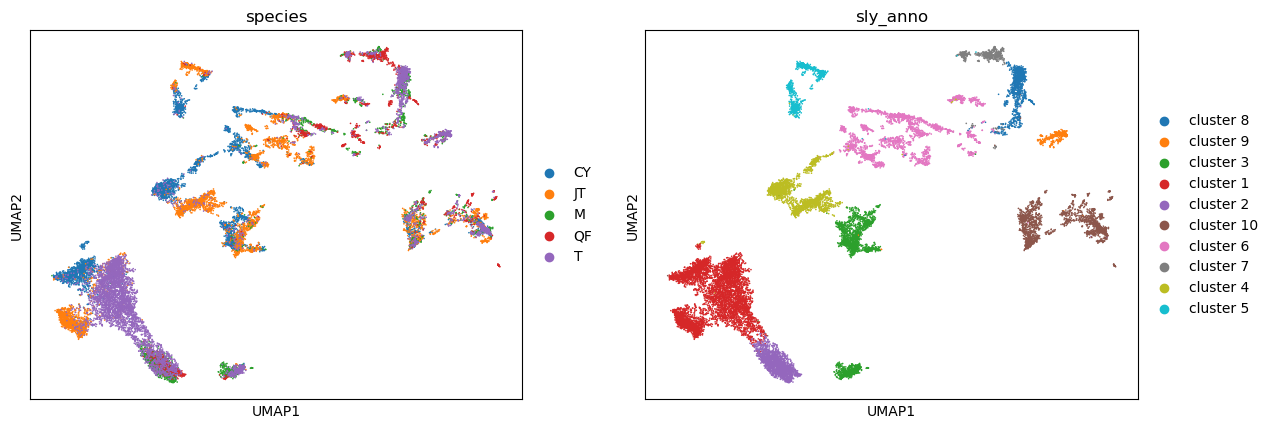

In [2]:
scdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/Finished_analysis/celltype_check/multi_raw.h5ad')
sc.pl.umap(scdata, color = ['species','sly_anno'])


In [3]:
data_dic = {}

for species in scdata.obs.species.unique():

    adata = scdata[scdata.obs.species == species]
    # print(f'{species} {adata.shape}')

    # sc.pp.neighbors(adata, use_rep = 'X_pca_harmony')
    # sc.tl.leiden(adata, resolution = 0.15)
    # sc.pl.umap(adata, color = 'leiden')
    data_dic[species] = adata

In [4]:
# species_list = scdata.obs.species.unique()
# cluster_embed = {}
# species_pos = {}

# tmp = 0
# for species in species_list:
#     adata = data_dic[species]
#     cluster_ids = np.sort(adata.obs.leiden.unique().astype('object'))

#     for idx in cluster_ids:
#         sel_id = adata.obs.leiden == idx 
#         pca_embed = adata.obsm['X_pca_harmony'][sel_id,:]
#         cluster_embed[f'{species}_{idx}'] = pca_embed.mean(axis=0)
    
#     species_pos[species] = (tmp, tmp + len(cluster_ids))
#     tmp += len(cluster_ids)

# cluster_df = pd.DataFrame(cluster_embed).T
# from scipy.spatial.distance import pdist, squareform

# cluster_cluster_weight = squareform(pdist(cluster_df.values, metric='correlation')) # metric = 'cosine
# cluster_cluster_weight = pd.DataFrame(cluster_cluster_weight, index=cluster_df.index, columns=cluster_df.index)

# weight_copy =  cluster_cluster_weight.copy()

In [5]:
# ## normalize cross species cluster weight 

# idx = np.arange(len(weight_copy))

# for species in species_list:
#     for com_species in species_list:

#         if species == com_species:
#             a,b = species_pos[species]

#             sel_index = idx[a:b]
#             cross_df = weight_copy.iloc[sel_index, sel_index]
#             for i in range(cross_df.shape[0]):
#                 cross_df.iloc[i,i] = np.inf            
#             cluster_cluster_weight.iloc[sel_index, sel_index] = softmax(-cross_df.values, tau = 0.1)
            
#         else:
#             a,b = species_pos[species]
#             c,d = species_pos[com_species]

#             sel_index = idx[a:b]
#             sel_columns = idx[c:d]
#             cross_df = weight_copy.iloc[sel_index, sel_columns]
#             cluster_cluster_weight.iloc[sel_index, sel_columns] = softmax(-cross_df.values, tau = 0.1)

# for i in range(cluster_cluster_weight.shape[0]):
#     cluster_cluster_weight.iloc[i,i] = 1

# cluster_cluster_weight = (cluster_cluster_weight + cluster_cluster_weight.T)/2

# sns.heatmap(cluster_cluster_weight, cmap = 'coolwarm')
# plt.show()

### modify不合理的边 

原始的knn 图 id --> adata 中 的id 

In [4]:
s_node2id = {}

for species in['CY','JT','T','M','QF']:
    adata = data_dic[species]
    tmp = {}
    for i,idx in enumerate(adata.obs.index.values):
        tmp[idx] = i 
    s_node2id[species] = tmp


node2id = {}

for i,idx in enumerate(scdata.obs.index.values):
    species = idx.split('-')[0][:-2]
    node2id[idx] = s_node2id[species][idx]

id2node = {}
for key in node2id.keys():
    id2node[node2id[key]] = key

## NOT USED

In [5]:
# 获取 dist 矩阵
raw_dist = scdata.obsp['connectivities'].toarray()

In [8]:
t_idx = np.logical_and(scdata.obs.species == 'T', scdata.obs.new_anno == 'DG Glut-(non eco)')  # 分错的猪尾鼠id
n_idx = np.logical_and(scdata.obs.species.isin(['M','QF']), scdata.obs.new_anno == 'DG Glut-(non eco)') # 全部非回声猪尾鼠id
e_idx = np.logical_and(scdata.obs.species.isin(['T']), scdata.obs.new_anno == 'DG Glut-(eco)') #正确的猪尾鼠id 
all_e_idx = scdata.obs.new_anno == 'DG Glut-(eco)'  ## 全部回声物种id

print(t_idx.sum(), e_idx.sum(), n_idx.sum(), all_e_idx.sum())
idx = np.arange(scdata.shape[0])
t_idx = idx[t_idx]
n_idx = idx[n_idx]
e_idx = idx[e_idx] 
all_e_idx = idx[all_e_idx]

# 获取 dist 矩阵
dist = raw_dist.copy()

# 选取 92 % 的错分的猪尾鼠id 与 正确的猪尾鼠 id 建立连边, 

sel_id = np.random.choice(t_idx, int(0.9*len(t_idx)), replace=False)
dist[sel_id, :] = 0
dist[:,sel_id] = 0

res = []
for i in range(len(sel_id)):
    x = sel_id[i]
    N_x = np.random.choice(e_idx, 15, replace=False)
    tmp = 0.2*np.random.rand(15) #0.2*np.random.rand(10)
    dist[x, N_x] = tmp 
    dist[N_x, x] = tmp
    
# 非回声的物种和回声物种之间连边置0

#dist[n_idx,:][:,all_e_idx] = 0

#dist[all_e_idx,:][:,n_idx] = 0
from scipy.sparse import csr_matrix
csr_dist = csr_matrix(dist)

660 3274 1298 6006


In [15]:
N_x

array([17072, 19357, 21850, 18434, 20023, 18854, 21263, 21389, 17405,
       17958, 16339, 20672, 19557, 16663, 17218])

In [16]:
tmp

array([0.41154286, 0.4103597 , 0.23461292, 0.09774447, 0.07456288,
       0.23799015, 0.41301487, 0.08573516, 0.12993105, 0.23842715,
       0.20984738, 0.12744323, 0.38235011, 0.30993904, 0.41801504])

In [9]:
np.save('idx.npz',scdata.obs.index[sel_id])

In [49]:
x1.mean()

1.0014317

In [50]:
x2.mean() / 15

0.4364614168802897

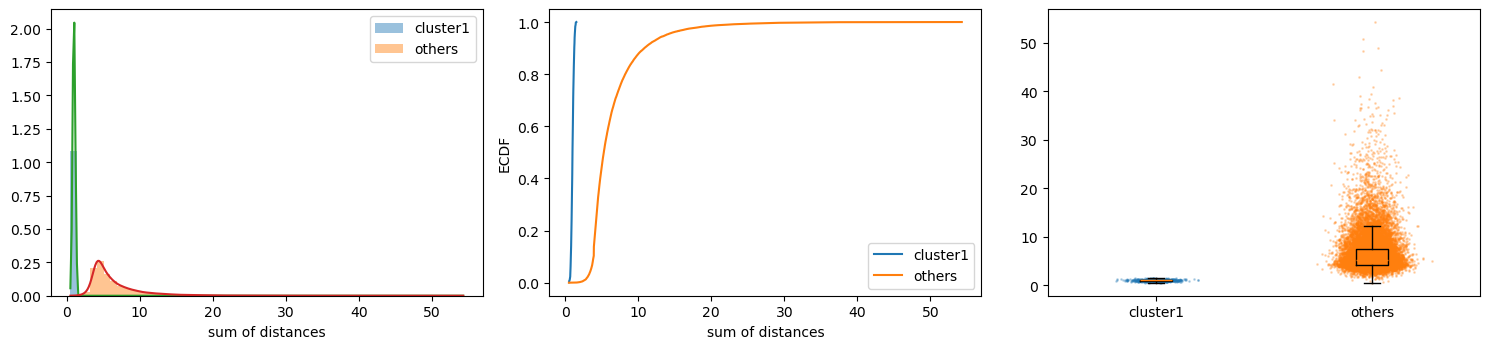

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))

# 1) 直方图 + KDE 叠加
lo, hi = min(x1.min(), x2.min()), max(x1.max(), x2.max())
bins = np.linspace(lo, hi, 60)
ax[0].hist(x1, bins=bins, density=True, alpha=.45, label='cluster1')
ax[0].hist(x2, bins=bins, density=True, alpha=.45, label='others')
xs = np.linspace(lo, hi, 300)
for x in (x1, x2):
    ax[0].plot(xs, stats.gaussian_kde(x)(xs))
ax[0].set_xlabel('sum of distances'); ax[0].legend()

# 2) ECDF（比直方图稳，不用挑 bin；看分布差异最直观）
for x, lab in [(x1, 'cluster1'), (x2, 'others')]:
    v = np.sort(x)
    ax[1].plot(v, np.arange(1, v.size + 1) / v.size, label=lab)
ax[1].set_xlabel('sum of distances'); ax[1].set_ylabel('ECDF'); ax[1].legend()

# 3) 箱线 + 抖动
ax[2].boxplot([x1, x2], showfliers=False)
ax[2].scatter(np.random.normal(1, .06, x1.size), x1, s=1, alpha=.25)
ax[2].scatter(np.random.normal(2, .06, x2.size), x2, s=1, alpha=.25)
ax[2].set_xticklabels(['cluster1', 'others'])

plt.tight_layout()

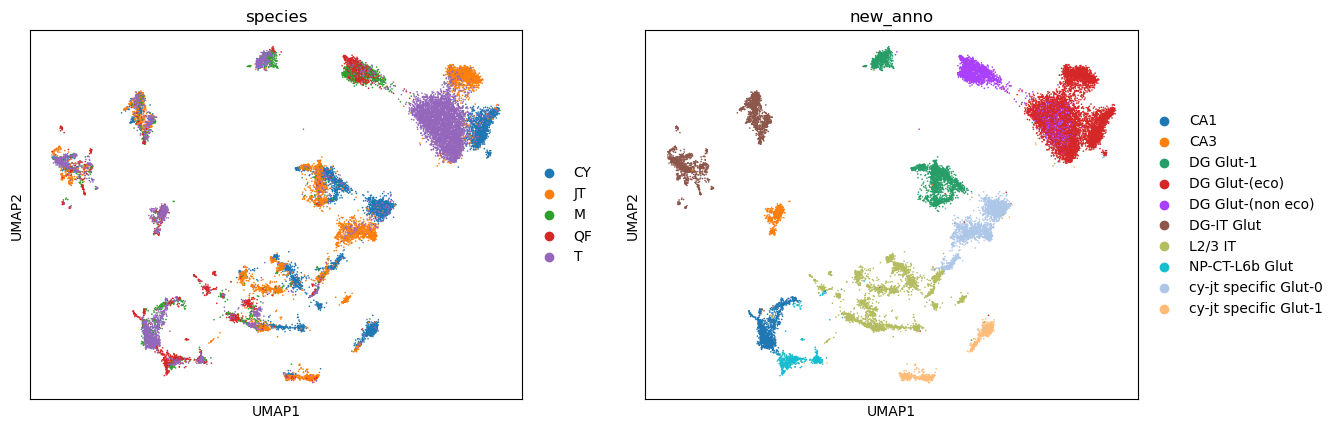

In [10]:
scdata.obsp['connectivities'] = csr_dist 
sc.tl.umap(scdata,min_dist=0.1)
sc.pl.umap(scdata, color = ['species','new_anno'])

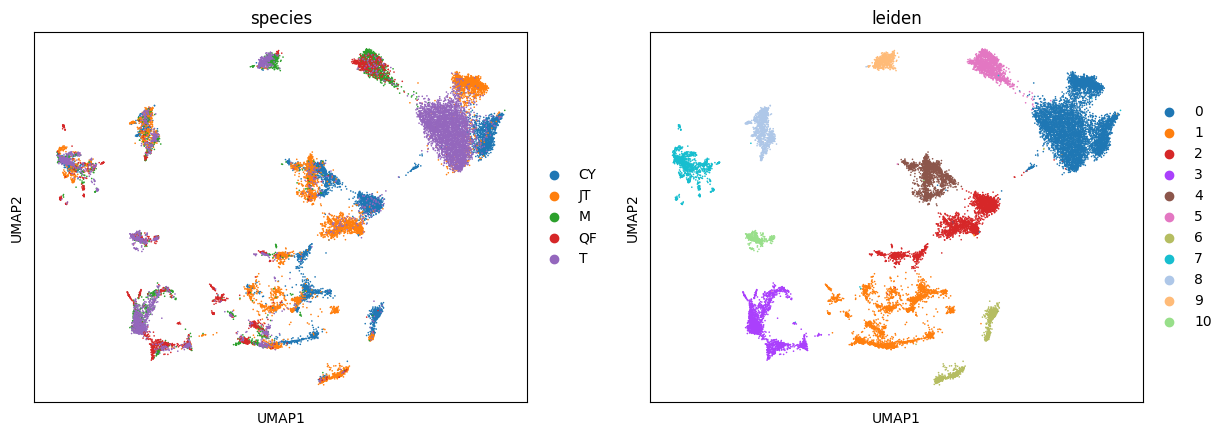

In [160]:
sc.tl.leiden(scdata, resolution = 0.3)
sc.pl.umap(scdata, color = ['species','leiden'])

In [164]:
scdata.write('modify_multi.h5ad')

In [161]:
pd.crosstab(scdata.obs.species, scdata.obs.leiden)

leiden,0,1,2,3,4,5,6,7,8,9,10
species,,,,,,,,,,,
CY,1375,871,1161,3,784,0,631,208,281,49,0
JT,1368,1002,1188,25,863,8,569,272,452,37,5
M,6,211,41,570,26,877,4,154,133,285,138
QF,2,551,35,572,11,407,15,236,43,21,140
T,3880,203,151,796,62,58,25,361,171,260,264


6019


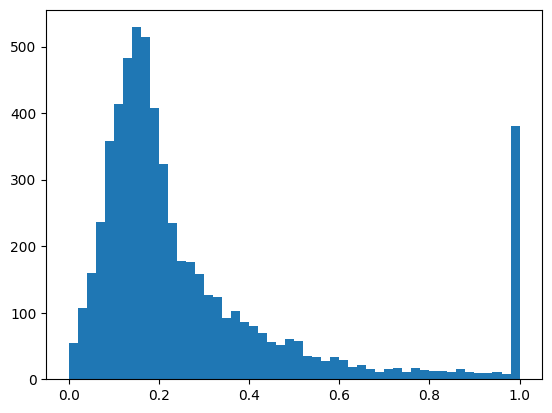

In [49]:
tmp = dist[t_idx,:][:,e_idx].flatten()
print((tmp > 0).sum())
tmp = tmp[tmp > 0]
plt.hist(tmp, bins = 50)
plt.show()

In [44]:
tmp.max()

1.0

(477903321,)
(472430,)


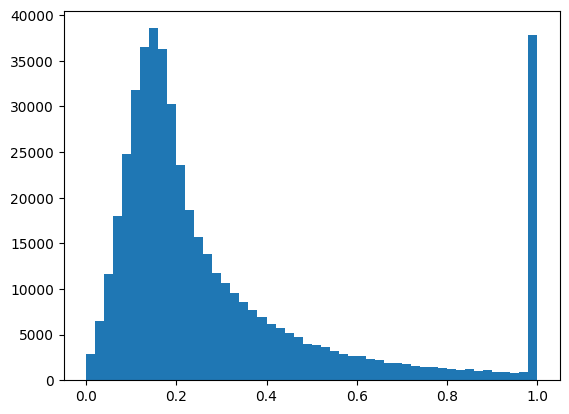

In [32]:
dist = scdata.obsp['connectivities'].toarray()

import matplotlib.pyplot as plt 

tmp = dist.flatten()
print(tmp.shape)
tmp = tmp[tmp>0]
print(tmp.shape)

plt.hist(tmp, bins = 50)
plt.show()

In [ ]:
t_idx = scdata.